In [1]:
import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

import scanpy as sc
#import squidpy as sq
import anndata as ad

import warnings
import squidpy as sq

  
warnings.simplefilter("ignore", category=UserWarning)

warnings.simplefilter("ignore", category=FutureWarning)  

/software/cellgen/team298/ls34/vqgraph/lib/python3.10/site-packages/anndata/utils.py:429: FutureWarning: Importing read_csv from `anndata` is deprecated. Import anndata.io.read_csv instead.
  warnings.warn(msg, FutureWarning)
/software/cellgen/team298/ls34/vqgraph/lib/python3.10/site-packages/anndata/utils.py:429: FutureWarning: Importing read_excel from `anndata` is deprecated. Import anndata.io.read_excel instead.
  warnings.warn(msg, FutureWarning)
/software/cellgen/team298/ls34/vqgraph/lib/python3.10/site-packages/anndata/utils.py:429: FutureWarning: Importing read_hdf from `anndata` is deprecated. Import anndata.io.read_hdf instead.
  warnings.warn(msg, FutureWarning)
/software/cellgen/team298/ls34/vqgraph/lib/python3.10/site-packages/anndata/utils.py:429: FutureWarning: Importing read_loom from `anndata` is deprecated. Import anndata.io.read_loom instead.
  warnings.warn(msg, FutureWarning)
/software/cellgen/team298/ls34/vqgraph/lib/python3.10/site-packages/anndata/utils.py:429: 

In [2]:
#PATH = '/nfs/team298/ls34/adult_skin/final_adatas/adata_combined_new.h5ad.final.filtered'
PATH ='/nfs/team298/ls34/adult_skin/final_adatas/adata_combined_new.h5ad.final.filtered.addrelapse'

adata=sc.read_h5ad(PATH)

adata.obs.dataset_id.value_counts()

 

dataset_id
nan                           1670528
Reynolds                       270768
Fiskin_AD                      258665
Luc_Psoriasis                  200265
Ganier_BCC                     150893
Ahlers_Dermalsheath             94951
Ma_Psoriasis                    84340
Church_Healthy                  74402
bullous_pemphigoid              53824
Rojahn_AD                       49822
Dunlap_Lupus                    49821
Direder_Keloid                  47256
Greenleaf_AA                    41131
Ji_SCCarcinoma                  34340
Sole-Boldo                      27273
Kersh_Lichen planus             22686
Tabib_SSc                       22486
Ma_SSc                          21283
Ma_Prurigo                      20892
Dobie_Dupuytren                 20052
LocalSSc_Hutchins               18152
Weidmann_Healthy                17922
Jiang_Lyme                      17215
Kim_DRESS                       14655
Bangert_AD                      14493
Deng_Keloid                     11777
S

In [3]:
# exclude transitioning treatment
adata = adata[adata.obs['Sanger patient ID']!="BK21"]

In [4]:
adata

View of AnnData object with n_obs × n_vars = 3370853 × 4993
    obs: 'sample_id', 'barcode', 'GSE', 'Site_status', 'Patient_status', 'Location', 'Age', 'Sex', 'dataset_id', 'n_genes_by_counts', 'total_counts', 'pct_counts_in_top_50_genes', 'lvl5_annotation', 'Mapping_status', 'scanvi_predictions', 'lvl4_annotation', 'lvl0', 'Site_status_simple', 'StatusMilo', 'atlas_status', 'atlas_status_reynolds', 'atlas_status_reynolds_simple', 'atlas_status_simple', 'atlas_status_simple2', 'Site_status_binary', 'cell_id', 'x_centroid', 'y_centroid', 'transcript_counts', 'control_probe_counts', 'genomic_control_counts', 'control_codeword_counts', 'unassigned_codeword_counts', 'deprecated_codeword_counts', 'cell_area', 'nucleus_area', 'nucleus_count', 'segmentation_method', 'log1p_n_genes_by_counts', 'log1p_total_counts', 'pct_counts_in_top_10_genes', 'pct_counts_in_top_20_genes', 'pct_counts_in_top_150_genes', 'n_counts', 'Sanger patient ID', 'Drug', 'Timepoint', 'DonorID', 'disease_overall', 'lvl0_

In [5]:
adata.obs.all_vs_core.value_counts()

all_vs_core
core       2930059
relapse     440794
Name: count, dtype: int64

In [6]:
adata[adata.obs.data_addition!="new_relapse"].obs["Site_status"].value_counts()

Site_status
Non-lesional                         1330227
Lesional                              526974
Healthy                               202749
3D_Week12                             180311
3D_Lesional_baseline                  153479
Week 12                               140302
PostRx                                 96485
Psoriasis_replicate_non-lesional       76048
Remission_longterm (past)              75050
Remission_longterm (never)             74463
Week 8 Psoriasis                       72094
Psoriasis_replicate_Lesional           60647
Psoriasis_replicate_PostRx             49385
Day 14_HF                              30438
Relapse                                25836
Remission_longterm (week 8)            23372
PostRx-Lesional Dupilumab (16 wk)       6694
PostRx-Lesional Dupilumab (1 yr)        4226
Name: count, dtype: int64

In [7]:
adata.obs.Site_status.value_counts()

Site_status
Non-lesional                         1330227
Lesional                              526974
Healthy                               202749
3D_Week12                             180311
3D_Lesional_baseline                  153479
Week 12                               140302
Remission_longterm (past)             140285
Remission_longterm (never)            127032
Relapse                               102198
PostRx                                 96485
Psoriasis_replicate_non-lesional       76048
Week 8 Psoriasis                       72094
Remission_longterm (week 8)            71279
Psoriasis_replicate_Lesional           60647
Psoriasis_replicate_PostRx             49385
Day 14_HF                              30438
PostRx-Lesional Dupilumab (16 wk)       6694
PostRx-Lesional Dupilumab (1 yr)        4226
Name: count, dtype: int64

In [8]:
adata.obs.Site_status.isna().sum()

0

In [9]:
adata[adata.obs.Site_status=="Relapse"].obs.info_id6.value_counts()

info_id6
BK72_Relapse        27877
BK74_Relapse        18584
BK70_Relapse        15111
BK73_Relapse        14790
BK51_wk8 Relapse    14433
BK49_wk8 Relapse    11403
Name: count, dtype: int64

In [10]:
adata.obs.Patient_status.value_counts()


Patient_status
AD                               930543
Healthy                          890036
Psoriasis                        563958
relapse                          242073
nan                              186080
3d_Lesional_baseline             175557
3d_Week12                        158233
Bullous pemphigoid                53824
SCC                               34340
Lichen planus                     22686
Prurigo                           20892
Dupuytren                         20052
Lyme_disease/Erythema migrans     17215
SCLE                              14257
Vitiligo                          11513
PSM                                9781
DLE                                7939
Wound                              7801
irAE                               4073
Name: count, dtype: int64

In [11]:
adata = adata[adata.obs["tech"]=="xenium"].copy()

In [12]:
# adata.obs.Site_status_binary.value_counts()

In [13]:
# [x for x in adata.obs["info_id6"].unique() if "relapse" in x.lower()]

In [14]:
# KEEP = ['BK43', 'BK46', 'BK49', 'BK50', 'BK51']

# vals = adata.obs["info_id6"].astype(str).unique()

# hits = [
#     v for v in vals
#     if any(k in v for k in KEEP)
# ]

# print(hits)


In [15]:
colors_new2 = {
        'Epidermis_basal': "#4a538f",# "#3489f1", #"#000080", #"#f0f8ff", #"#007cfe",#'#4f59a1',  # dark blue
    "Epidermis basal":"#3489f1",# "#000080", #"#f0f8ff", #"#000080",
    
                'Epidermis_mid': '#F0F8FF', # #e3e7eb - GREY
  #  "Epidermis_late": "#4682B4", #"#A52A2A",          # pink
            'Epidermis_late':"#2a2f5c",#"#2a2f5c" ,# "#2e2e2e",#'#b1dae6',  # light blue

   'Epidermis basal_cycling': "#007cfe",  #  e2d8dd   "#505aa1",#"#c590a5" , # '#e0c5d2',
'Epidermis_basal_cycling': "#007cfe", 
'EpidermisInflamm_mid':"#f6e3ec",
        'EpidermisInflamm_late': "#800020",
    
    
    # 'Epidermis_Inflammatory': '#f2e7ed',
        "Epidermis_APChi": "#ff1493",
    'Papillary_dermis':"#FFFF00", # "#f6d17a", # yellow
    
  #  'Perivascular':  "#845DAE", #  '#fedbe7' PINKSIH,  #'#f8daeb',  # darkish red
    'Small blood vessel': "#d73435", #'#fe78bb',  # bright red
    'Sweat_gland': '#008080',  # dark grey
        'Sweat_gland_channel': "#adf7e8", #'#008080',  # original - 40E0D0
    'Muscle': "#f371af",  # very dark red
    'Adipocyte+vessels': "#B8860B", #'#FF4500',  # very dark orange
     'Hypodermis': "#FFFFF0", #"#D2B48C",#' # yello  # white = '#ffffff',
    'Larger blood vessel': "#660000",#"#8B0000", #'#FF6347',  # coral red
    'Perineural': '#0A0A0A',  # almost black
   # 'Plasma+pDC': '#808080',  # bright turquoise
    #'Sweat gland channel': '#000000',  # black
    #'KC_immunecell': '#FF1493',  # dark pink
    
   # 'Epidermis_late': '#b1dae6',
    "Nonspecific":"#D3D3D3",
     'Reticular_dermis': '#d0e1f2',

 'Large_BV': '#660000',
 'Small_BV': "#c43f40",#'#D96B6B',
     'Tzone-like': "#845DAE",# '#F4D1A1',

 'Sebaceous_gland': "#FFD9A3",      #  "#FFB347",#"#94cb72",#'#e28743',
"Sebaceous_immune": "#ff6145", 
 #'Plasma_cell_niche': "#1F51FF", #"#FFB300",#"#40E0D0",#'#ff5e00',
   # 'Plasma_cell_rich':  "#8080B2", #"
"Plasma_cell_rich": "#04D9FF",
    'HF_Perineural': '#00FF00',
    "OuterHF": "#006600",# 
 'Sebaceous duct': '#e28743',


"Lymphoid Tzone-like": "#825bac",
    



     #007FFF
    "Reticular_dermis_LE_rich" : "#6A8ED8",
        "Reticular_dermis_LErich" : "#6A8ED8",
    "Small_BV_Trich": "#FFB6C1",          # neon orange
    "Tzone-like_Theavy": "#B19CD9",       # light purple
    #"Reticular dermis_F2/F3hi": "#35476C", #"#FF5F1F",# light blue
    "HF_outer": "#90c670",                # very dark green
    "VenuleMuscle": "#B34A7E",

    "Sebaceous_duct": "#FFA07A",          # light orange (salmony)
    "VenuleEndothelium": "#8B0000",       # dark red
    "HF_inner": "#90EE90",                 # light green
    "HF_TNN+COCH+hi": "#39FF14",          # neon green
    # "Peri_sweat_gland": "#d9f9f7",
    'HF_innermost':  "#D95D54",
  #  'Sebaceous_inner_immune':"#F6A85C",
    'Nonspecific/folded': "#F0F0F0",
 'nan': '#FAFAFA'
    }

# sc.settings.set_figure_params(dpi=50, facecolor="white", frameon=False, figsize=(30,30))

# adata.obs['niche17'] =adata.obs['niche17'] .astype('category')
# adata.uns['niche17_colors'] = [colors_new2.get(cat, '#D3D3D3')  # Default to light grey if not found
#                                      for cat in adata.obs['niche17'].cat.categories]
    
# sc.pl.umap(adata, 
#            color=["niche17"  ],
#            size=3, 
#            legend_loc="on data", 
#            vmax="p99", 
#            legend_fontsize=12,
#           legend_fontoutline=2,
#            linewidth=0.02,
#            edgecolor='white',
#           )
# sc.settings.set_figure_params(dpi=50, facecolor="white", frameon=False, figsize=(18,18))


In [16]:
adata.obs.Timepoint2.value_counts()

Timepoint2
nan                             579185
Non-lesional Baseline           246688
Lesional Baseline               219567
Week 12                         140302
Never Lesional                  109568
Relapse                          76362
Week 8 (resolved)                72094
Baseline past lesional           65235
Baseline never lesional          52569
Day 14_HF                        30438
Relapse (past lesional site)     27004
Week 8 past lesional             20903
Name: count, dtype: int64

In [17]:
adata.obs.Timepoint.value_counts()


Timepoint
nan                             579185
Non-lesional Baseline           246688
Lesional Baseline               219567
Week 12                         140302
Never Lesional                  109568
Relapse                          76362
Week 8 (resolved)                72094
Baseline past lesional           65235
Baseline never lesional          52569
Day 14_HF                        30438
Relapse (past lesional site)     27004
Week 8 past lesional             20903
Name: count, dtype: int64

In [18]:
# adata[adata.obs["Timepoint"]=="Week 8 (resolved)"].obs["Sanger patient ID"
#                                                       ].unique()

In [19]:
# KEEP = ['BK50_Past Lesional', 'BK49_Past Lesional wk8 relaspe', 'BK46_Never Lesional', 'BK51_Past Lesional wk8 relaspe', 'BK51_wk8 Relapse', 'BK46_Past Lesional', 'BK43_Past Lesional', 'BK43_Never Lesional', 'BK49_wk8 Relapse', 'BK49_Past Lesional', 'BK49_Never Lesional', 'BK51_Never Lesional', 'BK50_Never Lesional', 'BK51_Past Lesional']
# adata_i = adata[adata.obs["info_id6"].isin(KEEP)].copy()
# adata_i.shape
# adata_i.obs["Site_status"].value_counts()

In [20]:
KEEP = ["Remission_longterm (past)", "Remission_longterm (never)",
        "Relapse", "Remission_longterm (week 8)"]
adata_i = adata[adata.obs["Site_status"].isin(KEEP)].copy()


In [21]:
adata_i.obs["info_id6"].nunique()

29

In [22]:
# lesional = 6
# nonp-lesiaon

In [23]:
adata_i.obs["info_id6"].nunique()

29

In [24]:
adata_i.obs["info_id6"].value_counts()

info_id6
BK72_Relapse                         27877
BK49_Past Lesional                   27387
BK74_Baseline never lesional         24599
BK70_Week 8 past lesional            20903
BK46_Never Lesional                  18754
BK74_Relapse                         18584
BK46_Past Lesional                   18353
BK74_Relapse (past lesional site)    17601
BK74_Baseline past lesional          17381
BK70_Baseline past lesional          16999
BK72_Baseline past lesional          16497
BK51_Never Lesional                  15454
BK70_Relapse                         15111
BK73_Relapse                         14790
BK50_Never Lesional                  14673
BK51_wk8 Relapse                     14433
BK73_Baseline past lesional          14358
BK70_Baseline never lesional         13737
BK49_Never Lesional                  13472
BK49_Past Lesional wk8 relaspe       12682
BK51_Past Lesional                   12627
BK43_Never Lesional                  12110
BK49_wk8 Relapse                     11403
BK

In [25]:
adata_i[adata_i.obs.sample_id=="Sebaceous_duct"].obs.sample_id.value_counts()

Series([], Name: count, dtype: int64)

In [26]:
adata_i[adata_i.obs.sample_id=="BK49_wk8 Relapse"].obs.niche19.value_counts()

niche19
Small_BV                    3157
Epidermis_upper             2039
Epidermis_basal             1968
Papillary_dermis            1107
Reticular_dermis             928
Epidermis_mid                634
Muscle                       473
Sweat_gland_channel          368
Reticular_dermis_LE_rich     265
Large_BV                     194
Sweat_gland                  101
Perineural                    78
Tzone-like                    49
VenuleMuscle                  23
Hypodermis                    19
Name: count, dtype: int64

In [27]:
adata.obs["response"].value_counts()

response
nan        989851
relapse    242073
-4.65       79482
100.0       64938
81.5        53364
79.14       40442
6.43        40368
93.39       39148
94.44       36288
59.92       29908
82.1        24053
Name: count, dtype: int64

In [28]:
adata_i.obs["Timepoint"].value_counts()

Timepoint
Non-lesional Baseline           98422
Relapse                         76362
Never Lesional                  74463
Baseline past lesional          65235
Baseline never lesional         52569
Relapse (past lesional site)    27004
Lesional Baseline               25836
Week 8 past lesional            20903
Name: count, dtype: int64

In [29]:

adata_i.obs["Site_status"].value_counts()

Site_status
Remission_longterm (past)      140285
Remission_longterm (never)     127032
Relapse                        102198
Remission_longterm (week 8)     71279
Name: count, dtype: int64

In [30]:
RENAME = {"Lesional Baseline": "Relapse (week 8)"}
adata_i.obs["Timepoint"]=adata_i.obs["Timepoint"].map(RENAME).fillna(adata_i.obs["Timepoint"])

In [31]:


# # Copy obs to avoid side effects
# obs = adata_i.obs.copy()

# # Ensure categorical (important)
# obs["Timepoint"] = obs["Timepoint"].astype("category")
# obs["niche19"] = obs["niche19"].astype("category")

# # Contingency table: Timepoint × niche19
# ct = pd.crosstab(obs["Timepoint"], obs["niche19"])

# # Convert to proportions per Timepoint
# ct_prop = ct.div(ct.sum(axis=1), axis=0)

# # Ensure column order matches color dict keys
# ct_prop = ct_prop.loc[:, ct_prop.columns]

# # Build color list in column order
# colors = [colors_new2[n] for n in ct_prop.columns]

# # Plot
# fig, ax = plt.subplots(figsize=(8, 5))

# ct_prop.plot(
#     kind="bar",
#     stacked=True,
#     ax=ax,
#     color=colors,
#     edgecolor="black",
#     linewidth=0.3
# )

# ax.set_xlabel("Timepoint")
# ax.set_ylabel("Proportion of cells")
# ax.set_title("Proportion of niche19 across timepoints")

# ax.legend(
#     title="niche19",
#     bbox_to_anchor=(1.05, 1),
#     loc="upper left",
#     frameon=False
# )

# plt.tight_layout()
# plt.show()

In [32]:
# import pandas as pd
# import matplotlib.pyplot as plt

# # Copy obs
# obs = adata_i.obs.copy()

# # Ensure categorical
# obs["Timepoint"] = obs["Timepoint"].astype("category")
# obs["niche19"] = obs["niche19"].astype("category")

# NICHES = ["Sebaceous_immune", "Plasma_cell_rich"]

# # Full contingency table
# ct_all = pd.crosstab(obs["Timepoint"], obs["niche19"])

# # Subset columns of interest
# ct_sub = ct_all[NICHES]

# # Normalize by ALL cells per timepoint
# ct_prop = ct_sub.div(ct_all.sum(axis=1), axis=0)

# # Colors
# colors = [colors_new2[n] for n in ct_prop.columns]

# # Plot
# fig, ax = plt.subplots(figsize=(3, 4))

# ct_prop.plot(
#     kind="bar",
#     stacked=True,
#     ax=ax,
#     color=colors,
#     edgecolor="black",
#     linewidth=0.3
# )

# ax.set_xlabel("Timepoint")
# ax.set_ylabel("Proportion of all cells")
# ax.set_title("Stopping treatment (relapse)")

# ax.legend(
#     title="niche19",
#     frameon=False
# )

# plt.tight_layout()
# plt.show()
 

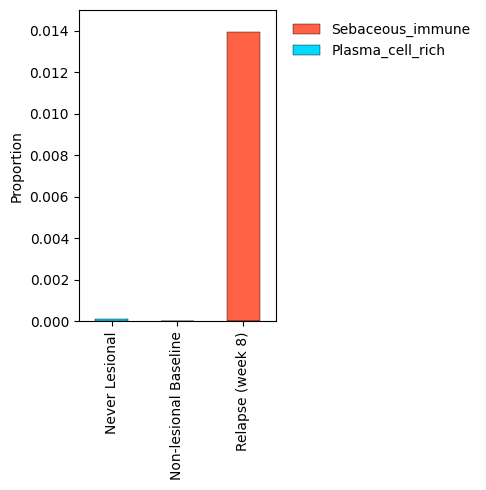

In [33]:
import pandas as pd
import matplotlib.pyplot as plt

# Copy obs
obs = adata_i.obs.copy()

# Ensure categorical
obs["Timepoint"] = obs["Timepoint"].astype("category")
obs["niche19"] = obs["niche19"].astype("category")

NICHES = ["Sebaceous_immune", "Plasma_cell_rich"]

# Desired x-axis order
ORDER = ["Never Lesional", "Non-lesional Baseline", "Relapse (week 8)"]

# Full contingency table
ct_all = pd.crosstab(obs["Timepoint"], obs["niche19"])

# Reorder rows
ct_all = ct_all.reindex(ORDER)

# Subset columns of interest
ct_sub = ct_all[NICHES]

# Normalize by ALL cells per timepoint
ct_prop = ct_sub.div(ct_all.sum(axis=1), axis=0)

# Colors
colors = [colors_new2[n] for n in ct_prop.columns]

# Plot
fig, ax = plt.subplots(figsize=(5, 5))

ct_prop.plot(
    kind="bar",
    stacked=True,
    ax=ax,
    color=colors,
    edgecolor="black",
    linewidth=0.3
)

# ---------------------------
# Formatting fixes
# ---------------------------

ax.set_ylim(0, 0.015)           # (1)
ax.set_ylabel("Proportion")    # (2)
ax.set_xlabel("")              # (6)

ax.legend(
    frameon=False,             # (5)
    bbox_to_anchor=(1.02, 1),  # (4)
    loc="upper left"
)

ax.set_title("")


plt.tight_layout()
fig.savefig("SUPPLEMENTARY_niches_relapse_hidden.pdf", dpi=300, bbox_inches="tight")
plt.show()

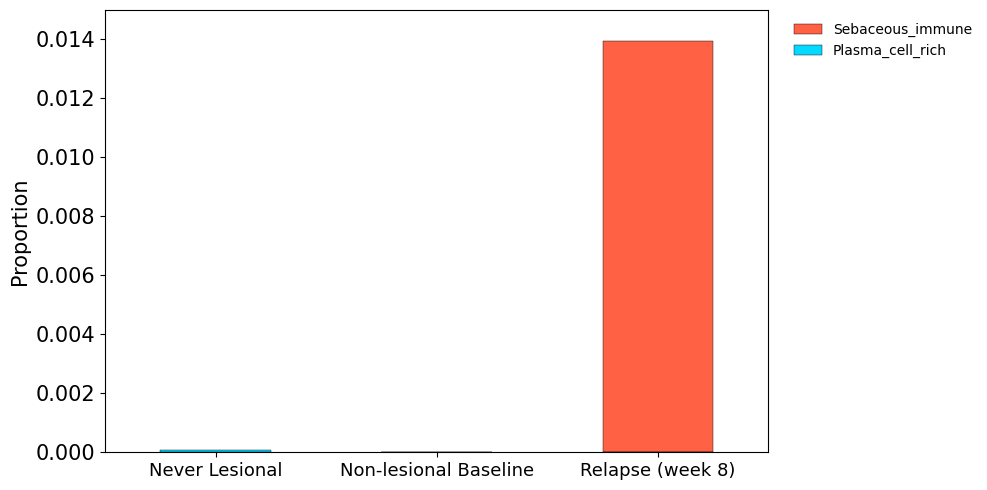

In [34]:
import pandas as pd
import matplotlib.pyplot as plt

# Copy obs
obs = adata_i.obs.copy()

# Ensure categorical
obs["Timepoint"] = obs["Timepoint"].astype("category")
obs["niche19"] = obs["niche19"].astype("category")

NICHES = ["Sebaceous_immune", "Plasma_cell_rich"]

# Desired x-axis order
ORDER = ["Never Lesional", "Non-lesional Baseline", "Relapse (week 8)"]

# Full contingency table
ct_all = pd.crosstab(obs["Timepoint"], obs["niche19"])

# Reorder rows
ct_all = ct_all.reindex(ORDER)

# Subset columns of interest
ct_sub = ct_all[NICHES]

# Normalize by ALL cells per timepoint
ct_prop = ct_sub.div(ct_all.sum(axis=1), axis=0)

# Colors
colors = [colors_new2[n] for n in ct_prop.columns]

# Plot
fig, ax = plt.subplots(figsize=(10, 5))

ct_prop.plot(
    kind="bar",
    stacked=True,
    ax=ax,
    color=colors,
    edgecolor="black",
    linewidth=0.3
)

# ---------------------------
# Formatting fixes
# ---------------------------

ax.set_ylim(0, 0.015)           # (1)
ax.set_ylabel("Proportion", fontsize=15)    # (2)
ax.set_xlabel("")              # (6)
ax.set_xticklabels(ax.get_xticklabels(), rotation=0, fontsize=13)
ax.tick_params(axis="y", labelsize=15)


ax.legend(
    frameon=False,             # (5)
    bbox_to_anchor=(1.02, 1),  # (4)
    loc="upper left"
)

ax.set_title("")


plt.tight_layout()
fig.savefig("SUPPLEMENTARY_niches_relapse_hidden_v2.pdf", dpi=300, bbox_inches="tight")
plt.show()

In [35]:
# import pandas as pd
# import matplotlib.pyplot as plt

# # Copy obs
# obs = adata_i.obs.copy()

# # Ensure categorical
# obs["Timepoint"] = obs["Timepoint"].astype("category")
# obs["niche19"] = obs["niche19"].astype("category")

# NICHES = ["Sebaceous_immune", "Plasma_cell_rich"]

# # Full contingency table
# ct_all = pd.crosstab(obs["Timepoint"], obs["niche19"])

# # Subset columns of interest
# ct_sub = ct_all[NICHES]

# # Normalize by ALL cells per timepoint
# ct_prop = ct_sub.div(ct_all.sum(axis=1), axis=0)

# # Colors
# colors = [colors_new2[n] for n in ct_prop.columns]

# # Plot
# fig, ax = plt.subplots(figsize=(12, 5))

# ct_prop.plot(
#     kind="bar",
#     stacked=True,
#     ax=ax,
#     color=colors,
#     edgecolor="black",
#     linewidth=0.3
# )
# ax.set_xlabel("")
# ax.set_ylabel("Proportion", fontsize=14)
# ax.set_title("")

# ax.legend(
#     title="niche19",
#     frameon=False
# )
# #ax.tick_params(axis="x", rotation=0)
# ax.set_xticklabels(ax.get_xticklabels(), rotation=0, fontsize=13)
# ax.tick_params(axis="y", labelsize=14)

# ax.legend(
#     frameon=False,
#     fontsize=14,
#     title=None
# )
# fig.savefig("niches_relapse_hidden_v2.pdf", dpi=300, bbox_inches="tight")

# plt.tight_layout()
# plt.show()



In [36]:
MARKERS = {"CD8/CD4": ['CD8A', "CD4"],
        'Tissue-residency': ['ITGAE', 'CD109', 'ZNF683', 'ENTPD1'],
 'TRM_IL13': [ 'IL13', 'NBAS',# 'CCL17',
         'AREG', 'IL9R', 'PDLIM4', 
         'ZBTB16', 'KLRC4', 'ADGRG1', 'RGS9', 'KRT7', "CCL1", "CCR8" ],
 'TRM_IL17': ['IL17A',
  'IL17F',
  'CXCL13',
  'CCL20',
  'IL23R',
  'RORC',
  'ADAM12',  'LRRN3',
  'MYO7A',
  'IL21',  ],
    'Mixed': ['VDR','IL22', 

  'CTSH',

  'CCR6',
  'IL26', 'PTPN13',
         ],  
       
#  'Tissue-residency\n markers': ['CD8A', 'ITGAE', 'CD109', 'ZNF683', 'ENTPD1'],
#  'TRM_IL13': ['IL22', 'IL13', 'NBAS',# 'CCL17',
#          'AREG', 'IL9R', 'PDLIM4', 'CCR8',
#          'ZBTB16', 'KLRC4', 'ADGRG1', 'RGS9'],
#  'TRM_IL17': ['IL17A',
#   'IL17F',
#   'CXCL13',
#   'CCL20',
#   'IL23R',
#   'RORC',
#   'ADAM12',  'LRRN3',
#   'MYO7A',
#   'IL21',],
#     'Mixed': [

#   'CTSH',
#   'VDR',
#   'CCR6',
#   'IL26'
#          ],
#  'Other': ['PTPN13', #'ITGA1'
#           ],
#  'ITGA1hi': ['ITGA1', 'ZHX2', 'BICD1', 'PRR5L', 'ST8SIA1', 'ZNF407', "KLRG1"],
          }

In [37]:
def remove_markers(LIST):
    try: 
        LIST = {key: [gene for gene in genes if gene in adata.var_names] 
                           for key, genes in LIST.items()}
    except: 
        LIST =[gene for gene in LIST if gene in adata.var_names]
    return LIST


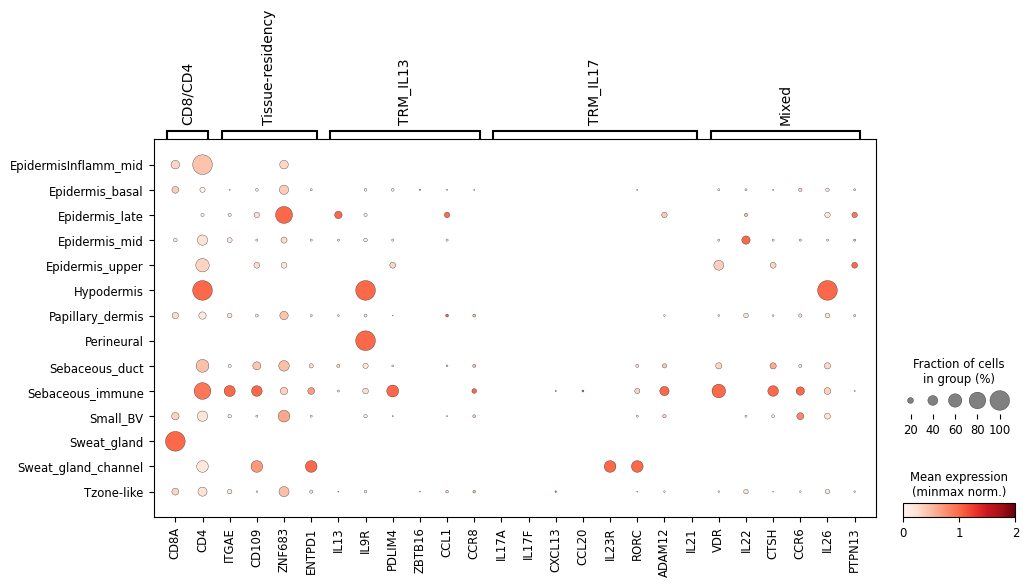

In [38]:
sc.pl.dotplot(
    adata_i[adata_i.obs["scanvi_predictions"]=="TRM_IL13+"],
    remove_markers(MARKERS),
    groupby="niche19",
  standard_scale="var",
    dendrogram=False,
    vmax=2,
    save="relapse_trm_phenotyping.pdf",
                               colorbar_title="Mean expression\n(minmax norm.)",
    #categories_order = ["Merkel cell", "ILC1", "ILC3", "ILC2"],

) 


In [39]:
adata_ii = adata_i[adata_i.obs["niche19"].isin(["Sebaceous_immune", "Tzone-like", "Sebaceous_duct", "Papillary_dermis",
 "Small_BV", "Epidermis_basal", "Sebaceous_gland"])]

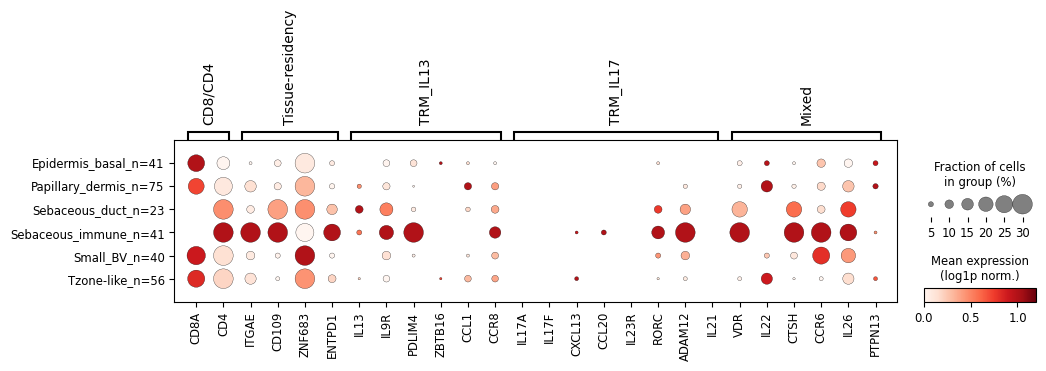

In [40]:
counts = adata_ii[adata_ii.obs["scanvi_predictions"] == "TRM_IL13+"].obs["niche19"].value_counts()
name_map = {k: f"{k}_n={v}" for k, v in counts.items()}

adata_ii.obs["niche19_counts"] = adata_ii.obs["niche19"].map(name_map)

sc.pl.dotplot(
    adata_ii[adata_ii.obs["scanvi_predictions"] == "TRM_IL13+"],
    remove_markers(MARKERS),
    groupby="niche19_counts",
    standard_scale="var",
    dendrogram=False,
    vmax=1.2,
    save="relapse_trm_phenotyping_onlybarplotvalues.pdf",
    colorbar_title="Mean expression\n(log1p norm.)",
    dot_max=0.3,
)

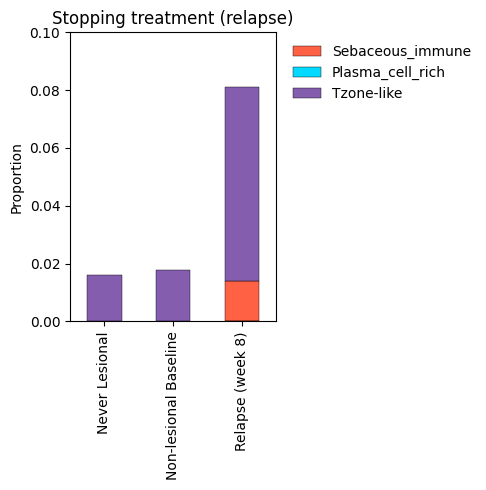

In [41]:
NICHES = ["Sebaceous_immune", "Plasma_cell_rich", "Tzone-like", "Epidermis_APChi"]
NICHES = [x for x in NICHES if x in adata_i.obs["niche19"].unique()]
import pandas as pd

import matplotlib.pyplot as plt

# Copy obs
obs = adata_i.obs.copy()

# Ensure categorical
obs["Timepoint"] = obs["Timepoint"].astype("category")
obs["niche19"] = obs["niche19"].astype("category")


# Desired x-axis order
ORDER = ["Never Lesional", "Non-lesional Baseline", "Relapse (week 8)"]

# Full contingency table
ct_all = pd.crosstab(obs["Timepoint"], obs["niche19"])

# Reorder rows
ct_all = ct_all.reindex(ORDER)

# Subset columns of interest
ct_sub = ct_all[NICHES]

# Normalize by ALL cells per timepoint
ct_prop = ct_sub.div(ct_all.sum(axis=1), axis=0)

# Colors
colors = [colors_new2[n] for n in ct_prop.columns]

# Plot
fig, ax = plt.subplots(figsize=(5, 5))

ct_prop.plot(
    kind="bar",
    stacked=True,
    ax=ax,
    color=colors,
    edgecolor="black",
    linewidth=0.3
)

# ---------------------------
# Formatting fixes
# ---------------------------

ax.set_ylim(0, 0.1)           # (1)
ax.set_ylabel("Proportion")    # (2)
ax.set_xlabel("")              # (6)

ax.legend(
    frameon=False,             # (5)
    bbox_to_anchor=(1.02, 1),  # (4)
    loc="upper left"
)

ax.set_title("Stopping treatment (relapse)")

fig.savefig("niches_remission_all.pdf", dpi=300, bbox_inches="tight")

plt.tight_layout()
plt.show()

In [42]:
# adata_i.obs

In [43]:
# Rename
adata_i.obs["Site_status"] = adata_i.obs["Site_status"].cat.rename_categories({
    "Remission_longterm (week 8)": "No disease signs (week 8)"
}) if hasattr(adata_i.obs["Site_status"], "cat") else adata_i.obs["Site_status"].replace({
    "Remission_longterm (week 8)": "No disease signs (week 8)"
})



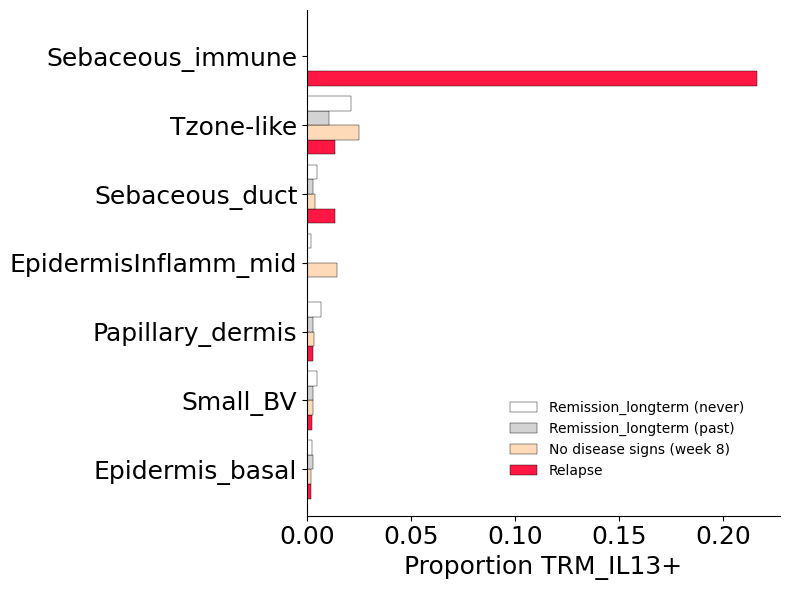

In [44]:
import pandas as pd
import matplotlib.pyplot as plt

total = adata_i.obs.groupby(["niche19", "Site_status"]).size().reset_index(name="total")
trm = adata_i.obs[adata_i.obs["lvl5_annotation"] == "TRM_IL13+"].groupby(["niche19", "Site_status"]).size().reset_index(name="trm")
merged = total.merge(trm, on=["niche19", "Site_status"], how="left")
merged["trm"] = merged["trm"].fillna(0)
merged["proportion"] = merged["trm"] / merged["total"]
props = merged.pivot(index="niche19", columns="Site_status", values="proportion").fillna(0)
props["_mean"] = props.mean(axis=1)
props = props.nlargest(7, "_mean").sort_values("_mean", ascending=True)
props = props.drop(columns="_mean")

colors = {
    "Remission_longterm (never)": "#FFFFFF",
    "Remission_longterm (past)": "#D3D3D3",
    "No disease signs (week 8)": "#FFDAB9",
    "Relapse": "#FF1744",
}

col_order = ["Remission_longterm (never)", "Remission_longterm (past)", "No disease signs (week 8)", "Relapse"]
col_order = col_order[::-1]
props = props[[c for c in col_order if c in props.columns]]
col_colors = [colors[c] for c in props.columns]

fig, ax = plt.subplots(figsize=(8, 6))
props.plot.barh(ax=ax, color=col_colors, edgecolor="black", linewidth=0.3, width=0.85)
ax.tick_params(axis='both', labelsize=18)
ax.set_xlabel("Proportion TRM_IL13+", fontsize=18)
ax.set_ylabel("")
ax.spines["right"].set_visible(False)
ax.spines["top"].set_visible(False)

handles, labels = ax.get_legend_handles_labels()
ax.legend(handles[::-1], labels[::-1], bbox_to_anchor=(0.95, 0.05), loc="lower right", frameon=False)

plt.tight_layout()
fig.savefig("4h_barplot_relapse.pdf", dpi=300, bbox_inches="tight")

plt.show()

In [53]:
adata_5k_i = adata[adata.obs.Site_status=="Relapse"]

In [56]:
CATEGORY="lvl5_annotation"
NICHE_COLUMN   = "niche19"
NICHE_COL=NICHE_COLUMN

0
Cell count for slide:  360

BK51_wk8 Relapse
1
2
3
4
5


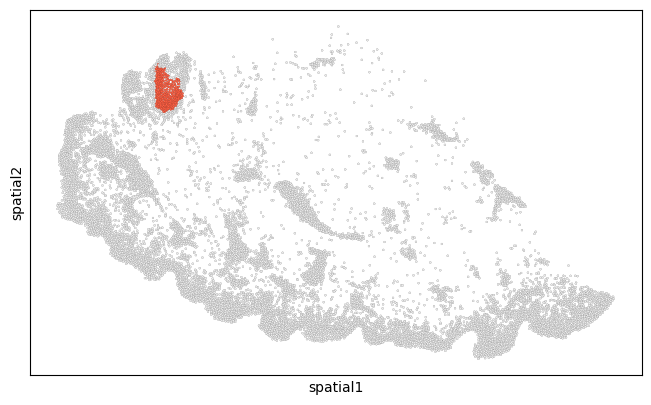

In [57]:
HIGHLIGHT_COLOR = "#ff6145"     # Red, as an example
OTHER_COLOR = "#ededed"         # Very light grey

NICHE="Sebaceous_immune"
#sc.settings.set_figure_params(dpi=100, facecolor="white", frameon=False, figsize=(18, 18))

 

sample_counts = adata_5k_i.obs["info_id6"].value_counts()
#samples_to_keep = sample_counts[sample_counts > 100].index

SEB_SAMPLES = []
for i, DONOR_ID in enumerate(adata_5k_i.obs.info_id6.unique()):
    adata_i = adata_5k_i[adata_5k_i.obs["info_id6"] == DONOR_ID]
    print(i)
    #print(i+1, "/", len(samples_to_keep))
    STATUS = adata_i.obs["Site_status"].unique()[0]
    TIMEPOINT = adata_i.obs["Timepoint"].unique()[0]
    DONOR = adata_i.obs["Sanger patient ID"].unique()[0]
    INFO_ID = list(adata_i.obs.info_id6.unique())[0]
    niche_names_found = adata_i.obs[NICHE_COLUMN].unique()
   
    if NICHE in niche_names_found:
        adata_ii = adata_i[adata_i.obs[NICHE_COLUMN] == NICHE]
        CELL_COUNT = adata_ii.shape[0]
        print("Cell count for slide: ", CELL_COUNT)
        print()
        if CELL_COUNT > 10:
            # 1. Make new obs column
            adata_i.obs[NICHE_COLUMN + "_highlight"] = adata_i.obs[NICHE_COLUMN].apply(
                lambda x: NICHE if x == NICHE else "Other"
            )
            # 2. Force categorical with desired order!
            adata_i.obs[NICHE_COLUMN + "_highlight"] = pd.Categorical(
                adata_i.obs[NICHE_COLUMN + "_highlight"],
                categories=[NICHE, "Other"],
                ordered=True
            )
            # 3. Palette as a list, not a dict
            palette = [HIGHLIGHT_COLOR, OTHER_COLOR]
            from matplotlib.colors import ListedColormap

            palette = ListedColormap([HIGHLIGHT_COLOR, OTHER_COLOR])
            # 4. Plot
            SEB_SAMPLES.append(DONOR_ID)
            print(DONOR_ID)
            sq.pl.spatial_scatter(
                adata_i,
                library_id="spatial",
                shape=None,
                color=NICHE_COLUMN + "_highlight",
                palette=palette,
                size=8,
                vmax=1,
                title='',
                #title=f"{DONOR_ID}_{STATUS}_{TIMEPOINT}_{DONOR}_n={CELL_COUNT}",
                edgecolor='black',
                linewidth=0.05,
                legend_loc=None,
                save=f"4h_sebimmune_nicheonly_{DONOR_ID}.pdf"
                # ax=ax,
                # legend_loc="on data"
            )

0
1
2
3
4
5


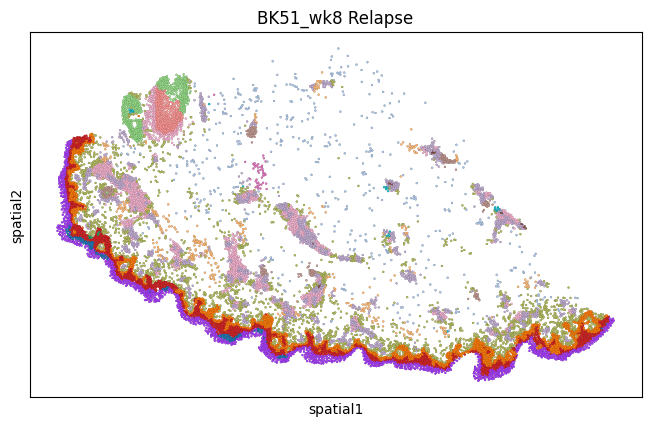

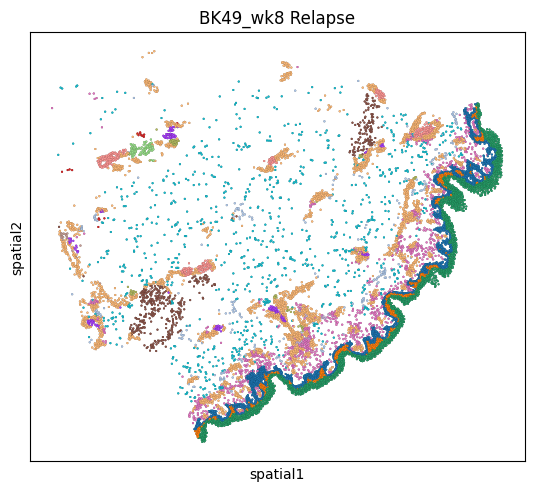

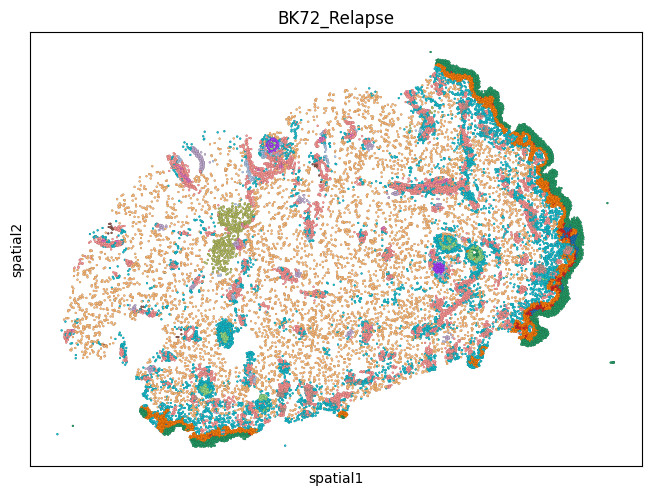

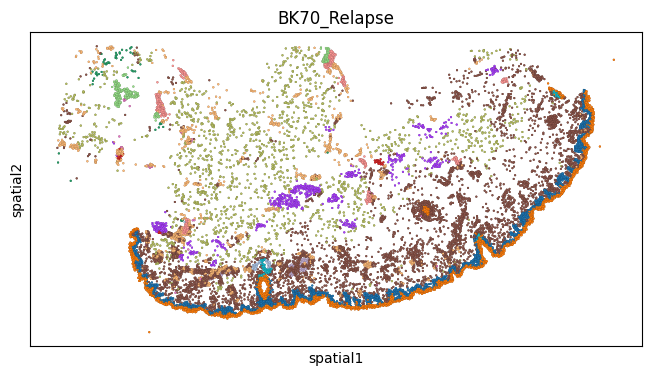

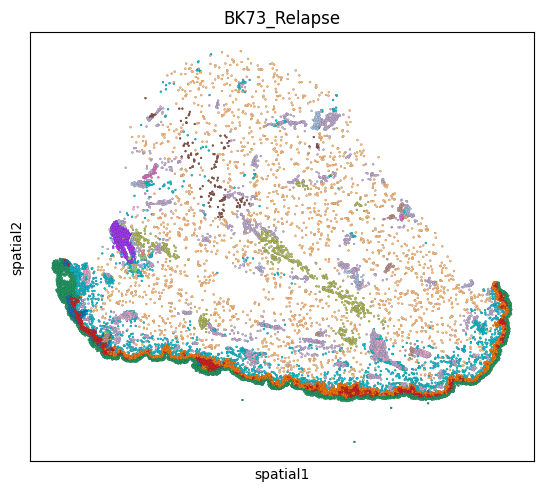

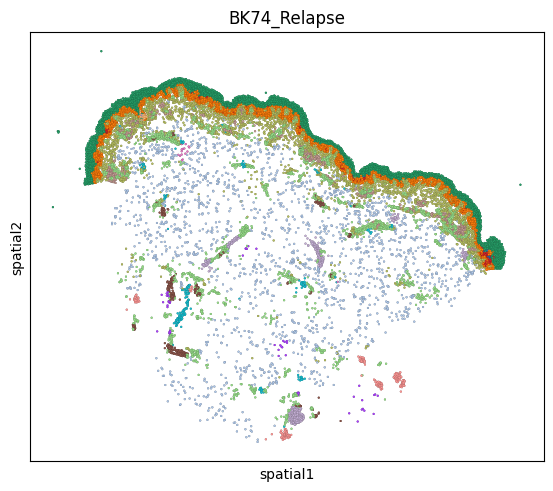

In [60]:
HIGHLIGHT_COLOR = "#ff6145"     # Red, as an example
OTHER_COLOR = "#ededed"         # Very light grey

NICHE="Sebaceous_immune"
#sc.settings.set_figure_params(dpi=100, facecolor="white", frameon=False, figsize=(18, 18))

 

sample_counts = adata_5k_i.obs["info_id6"].value_counts()
#samples_to_keep = sample_counts[sample_counts > 100].index

SEB_SAMPLES = []
for i, DONOR_ID in enumerate(adata_5k_i.obs.info_id6.unique()):
    adata_i = adata_5k_i[adata_5k_i.obs["info_id6"] == DONOR_ID]
    print(i)
    #print(i+1, "/", len(samples_to_keep))
    STATUS = adata_i.obs["Site_status"].unique()[0]
    TIMEPOINT = adata_i.obs["Timepoint"].unique()[0]
    DONOR = adata_i.obs["Sanger patient ID"].unique()[0]
    INFO_ID = list(adata_i.obs.info_id6.unique())[0]
    niche_names_found = adata_i.obs[NICHE_COLUMN].unique()
   
    #adata_ii = adata_i[adata_i.obs[NICHE_COLUMN] == NICHE]
#     CELL_COUNT = adata_ii.shape[0]
#     print("Cell count for slide: ", CELL_COUNT)
#     print()
#     if CELL_COUNT > 10:
#         # 1. Make new obs column
#         adata_i.obs[NICHE_COLUMN + "_highlight"] = adata_i.obs[NICHE_COLUMN].apply(
#             lambda x: NICHE if x == NICHE else "Other"
#         )
#         # 2. Force categorical with desired order!
#         adata_i.obs[NICHE_COLUMN + "_highlight"] = pd.Categorical(
#             adata_i.obs[NICHE_COLUMN + "_highlight"],
#             categories=[NICHE, "Other"],
#             ordered=True
#         )
#         # 3. Palette as a list, not a dict
#         palette = [HIGHLIGHT_COLOR, OTHER_COLOR]
#         from matplotlib.colors import ListedColormap

#         palette = ListedColormap([HIGHLIGHT_COLOR, OTHER_COLOR])
#         # 4. Plot
#         SEB_SAMPLES.append(DONOR_ID)
#         print(DONOR_ID)
    sq.pl.spatial_scatter(
        adata_i,
        library_id="spatial",
        shape=None,
        color=NICHE_COLUMN , #+ "_highlight",
      #  palette=palette,
        size=8,
        vmax=1,
        title=DONOR_ID,
        #title=f"{DONOR_ID}_{STATUS}_{TIMEPOINT}_{DONOR}_n={CELL_COUNT}",
        edgecolor='black',
        linewidth=0.05,
        legend_loc=None,
        #isave=f"4a_sebimmune_nicheonly_{DONOR_ID}.pdf"
        # ax=ax,
        # legend_loc="on data"
    )